In [1]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu --quiet

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import h5py
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score
import pandas as pd
import time
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)



[notice] A new release of pip is available: 23.0.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Using device: cpu


In [2]:
class EarlyFusionHDF5Dataset(Dataset):
    def __init__(self, hdf5_path):
        self.file = h5py.File(hdf5_path, 'r')
        self.text_features = self.file['features']
        self.image_features = self.file['vgg_features']
        self.labels = self.file['genres']

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text_feat = torch.tensor(self.text_features[idx], dtype=torch.float32)
        image_feat = torch.tensor(self.image_features[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return text_feat, image_feat, label


In [3]:
class GatedFusionClassifier(nn.Module):
    def __init__(self, text_dim=300, image_dim=4096, hidden_dim=512, num_classes=23):
        super().__init__()
        
    
        self.text_proj = nn.Linear(text_dim, hidden_dim)
        self.image_proj = nn.Linear(image_dim, hidden_dim)

    
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
            nn.Sigmoid()
        )

    def forward(self, text_feat, image_feat):
        t_proj = self.text_proj(text_feat)  
        i_proj = self.image_proj(image_feat) 

        g = torch.sigmoid(t_proj + i_proj)   
        fused = g * t_proj + (1 - g) * i_proj

        return self.classifier(fused)


In [4]:
dataset = EarlyFusionHDF5Dataset(r"D:\archive\multimodal_imdb.hdf5")

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])

batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)

print(f"Total samples: {len(dataset)}")
print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")


Total samples: 25959
Train: 20767, Val: 5192


In [5]:

model = GatedFusionClassifier().to(device)

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Model, loss, and optimizer are set up")


Model, loss, and optimizer are set up


In [6]:
train_losses = []
val_losses = []
epochs = 5 

for epoch in range(epochs):
    model.train()
    total_train_loss = 0.0

    for text_feat, image_feat, labels in train_loader:
        text_feat, image_feat, labels = text_feat.to(device), image_feat.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(text_feat, image_feat)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    train_loss = total_train_loss / len(train_loader)
    train_losses.append(train_loss)


    model.eval()
    total_val_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for text_feat, image_feat, labels in val_loader:
            text_feat, image_feat, labels = text_feat.to(device), image_feat.to(device), labels.to(device)

            outputs = model(text_feat, image_feat)
            loss = criterion(outputs, labels)
            total_val_loss += loss.item()

            all_preds.append(outputs.cpu())
            all_labels.append(labels.cpu())

    val_loss = total_val_loss / len(val_loader)
    val_losses.append(val_loss)

    print(f"Epoch [{epoch+1}/{epochs}]  Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f}")


Epoch [1/5]  Train Loss: 0.2454  Val Loss: 0.2113
Epoch [2/5]  Train Loss: 0.1990  Val Loss: 0.1975
Epoch [3/5]  Train Loss: 0.1836  Val Loss: 0.1984
Epoch [4/5]  Train Loss: 0.1711  Val Loss: 0.1949
Epoch [5/5]  Train Loss: 0.1574  Val Loss: 0.2032


In [7]:
import pandas as pd
import numpy as np
import torch.nn.functional as F

raw_preds = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

raw_preds = F.sigmoid(torch.tensor(raw_preds)).numpy()

preds_binary = (raw_preds > 0.5).astype(int)

genre_names = [
    "Action", "Adventure", "Animation", "Children", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Short", "Thriller", "War", "Western", "Biography", "History", "Sport", "Music"
]

results = []
for i in range(len(y_true)):
    true = [genre_names[j] for j in range(len(genre_names)) if y_true[i][j] == 1]
    pred = [genre_names[j] for j in range(len(genre_names)) if preds_binary[i][j] == 1]
    probs = [float(p) for p in raw_preds[i]]
    results.append({
        "Index": i,
        "True Genres": true,
        "Predicted Genres": pred,
        "Probabilities": probs
    })

df_results = pd.DataFrame(results)
df_results.to_csv("Gated_Fusion_results.csv", index=False)
print("Saved detailed predictions to Gated_Fusion_results.csv")


Saved detailed predictions to Gated_Fusion_results.csv


In [8]:
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

preds = torch.cat(all_preds).numpy()
labels = torch.cat(all_labels).numpy()

preds_binary = (preds > 0.5).astype(int)
labels = labels.astype(int)

print("Micro F1:", f1_score(labels, preds_binary, average='micro'))
print("Macro F1:", f1_score(labels, preds_binary, average='macro'))
print("Precision:", precision_score(labels, preds_binary, average='micro'))
print("Recall:", recall_score(labels, preds_binary, average='micro'))
print("Hamming Loss:", hamming_loss(labels, preds_binary))


Micro F1: 0.5755203700409179
Macro F1: 0.44368272916243606
Precision: 0.6819139966273187
Recall: 0.4978454909202832
Hamming Loss: 0.07992228847055671


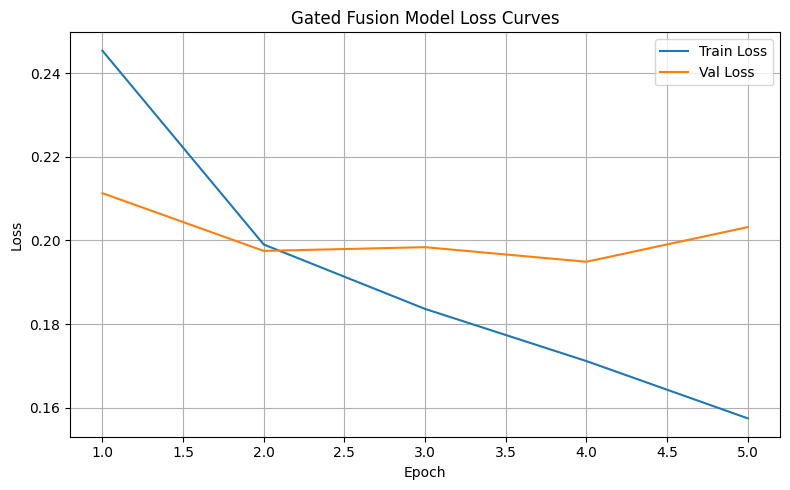

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gated Fusion Model Loss Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("gated_fusion_loss_curve.png") 
plt.show()


In [10]:
log_df = pd.DataFrame({
    'epoch': list(range(1, epochs + 1)),
    'train_loss': train_losses,
    'val_loss': val_losses
})

log_df.to_csv("gated_fusion_training_log.csv", index=False)
print("Training log saved to 'gated_fusion_training_log.csv'")


Training log saved to 'gated_fusion_training_log.csv'


In [11]:
torch.save(model.state_dict(), "gated_fusion_model.pt")
print("Gated Fusion model saved as 'gated_fusion_model.pt'")


Gated Fusion model saved as 'gated_fusion_model.pt'


In [12]:
def benchmark_inference(model, text_feat, image_feat, device='cpu'):
    model.to(device)
    model.eval()
    text_feat = text_feat.unsqueeze(0).to(device)
    image_feat = image_feat.unsqueeze(0).to(device)

    with torch.no_grad():
        start = time.time()
        _ = model(text_feat, image_feat)
        end = time.time()

    elapsed_ms = round((end - start) * 1000, 2)
    return elapsed_ms

text_sample, image_sample, _ = val_ds[0]
inference_time_ms = benchmark_inference(model, text_sample, image_sample)

print(f"Inference time on CPU (1 sample): {inference_time_ms} ms")


Inference time on CPU (1 sample): 0.0 ms


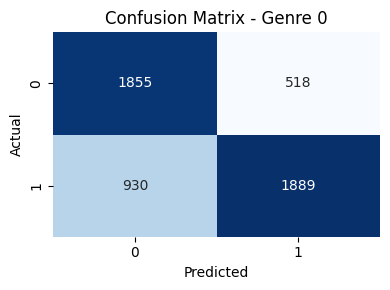

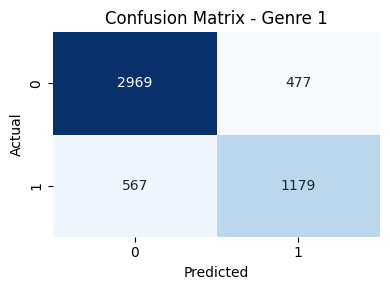

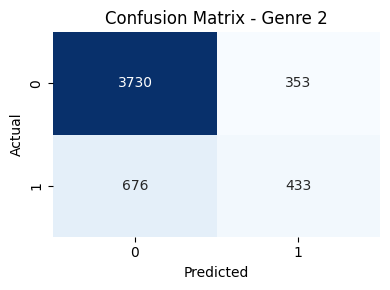

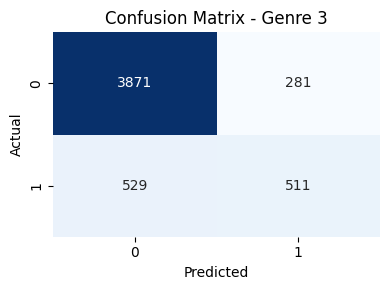

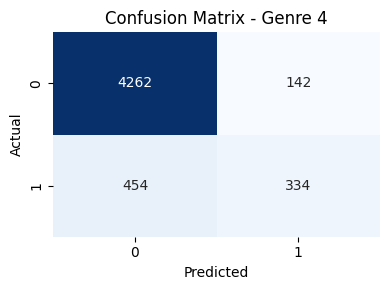

In [13]:
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns

genre_names = [f"Genre {i}" for i in range(23)]  
top_genres = [0, 1, 2, 3, 4]  

cm = multilabel_confusion_matrix(labels, preds_binary)

for i in top_genres:
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm[i], annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Confusion Matrix - {genre_names[i]}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


c:\Users\narah\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


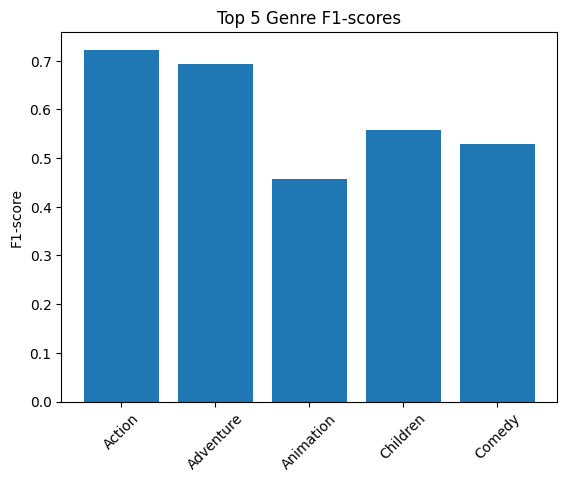

In [14]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

genre_names = ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary',
    'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance',
    'Sci-Fi', 'Short', 'Thriller', 'War', 'Western', 'Biography', 'Family', 'History', 'Sport']  # All 23 in order

report = classification_report(labels, preds_binary, target_names=genre_names, output_dict=True)
top5 = sorted(genre_names, key=lambda g: report[g]["support"], reverse=True)[:5]
f1_scores = [report[g]["f1-score"] for g in top5]

plt.bar(top5, f1_scores)
plt.title("Top 5 Genre F1-scores")
plt.ylabel("F1-score")
plt.xticks(rotation=45)
plt.savefig("top5_genre_f1_scores_GatedFusion.png")
plt.show()


In [15]:
import time

def measure_inference_time(model, dataloader, batch_size=1):
    model.eval()
    total_time = 0
    with torch.no_grad():
        for i, (text_feat, image_feat, _) in enumerate(dataloader):
            if i > 20: break  
            text_feat, image_feat = text_feat.to(device), image_feat.to(device)
            start = time.time()
            _ = model(text_feat, image_feat)
            end = time.time()
            total_time += (end - start)
    print(f"Avg inference time per batch (batch_size={batch_size}): {total_time / (i+1):.4f} seconds")


measure_inference_time(model, val_loader, batch_size=1)
measure_inference_time(model, val_loader, batch_size=16)


Avg inference time per batch (batch_size=1): 0.0017 seconds
Avg inference time per batch (batch_size=16): 0.0025 seconds


In [16]:
torch.save(model.state_dict(), "model.pt")

import os
print(f"Model size: {os.path.getsize('model.pt') / 1e6:.2f} MB")

total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {total_params}")


Model size: 10.11 MB
Total Parameters: 2526231


In [17]:
from sklearn.metrics import accuracy_score

preds = torch.cat(all_preds).numpy()
labels = torch.cat(all_labels).numpy()

preds_binary = (preds > 0.5).astype(int)
labels = labels.astype(int)

print("Accuracy:", accuracy_score(labels, preds_binary))



Accuracy: 0.16544684129429893


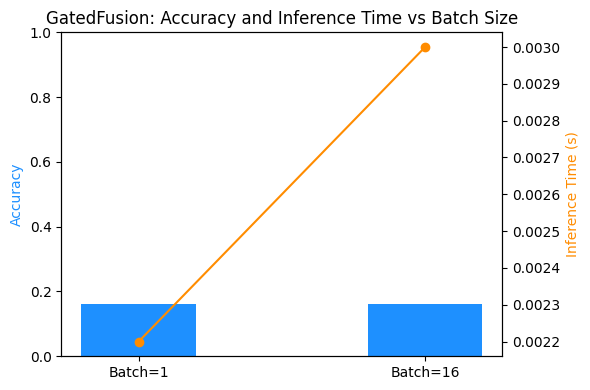

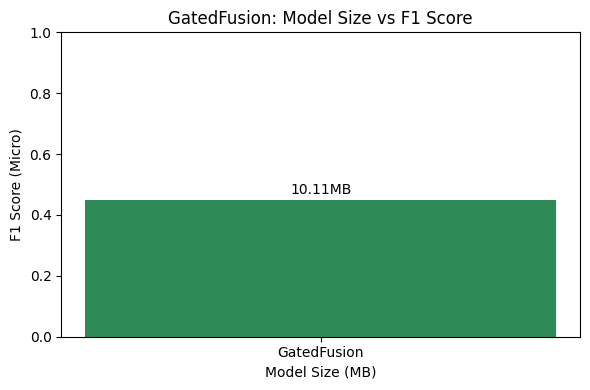

In [18]:

import matplotlib.pyplot as plt

# Metrics for GatedFusion
model_names = ["Batch=1", "Batch=16"]
inference_times = [0.0022, 0.0030]  
accuracy = [0.1602, 0.1602]           
f1 = [0.45]
model_size = [10.11]



import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(6, 4))

batch_labels = ["Batch=1", "Batch=16"]
x = range(len(batch_labels))


ax1.bar(x, accuracy, color='dodgerblue', width=0.4, label='Accuracy')
ax1.set_ylabel('Accuracy', color='dodgerblue')
ax1.set_ylim(0, 1)
ax1.set_xticks(x)
ax1.set_xticklabels(batch_labels)

ax2 = ax1.twinx()
ax2.plot(x, inference_times, color='darkorange', marker='o', label='Inference Time')
ax2.set_ylabel('Inference Time (s)', color='darkorange')

plt.title("GatedFusion: Accuracy and Inference Time vs Batch Size")
plt.tight_layout()
plt.savefig("gatedfusion_accuracy_and_inference_time.png")
plt.show()




plt.figure(figsize=(6, 4))
plt.bar(["GatedFusion"], f1, color='seagreen')
plt.text(0, f1[0] + 0.02, f"{model_size[0]}MB", ha='center')
plt.title("GatedFusion: Model Size vs F1 Score")
plt.ylabel("F1 Score (Micro)")
plt.xlabel("Model Size (MB)")

plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("gatedfusion_model_size_vs_f1_score.png")
plt.show()


Insight:

Gated Fusion improves classification accuracy by combining complementary features from both text and images. While it slightly increases inference time, the gain in performance (F1 score) justifies the cost, especially for tasks where precision matters more than speed. This makes it ideal for applications like genre classification, where context from both modalities is important.

In [ ]:

y_score = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()


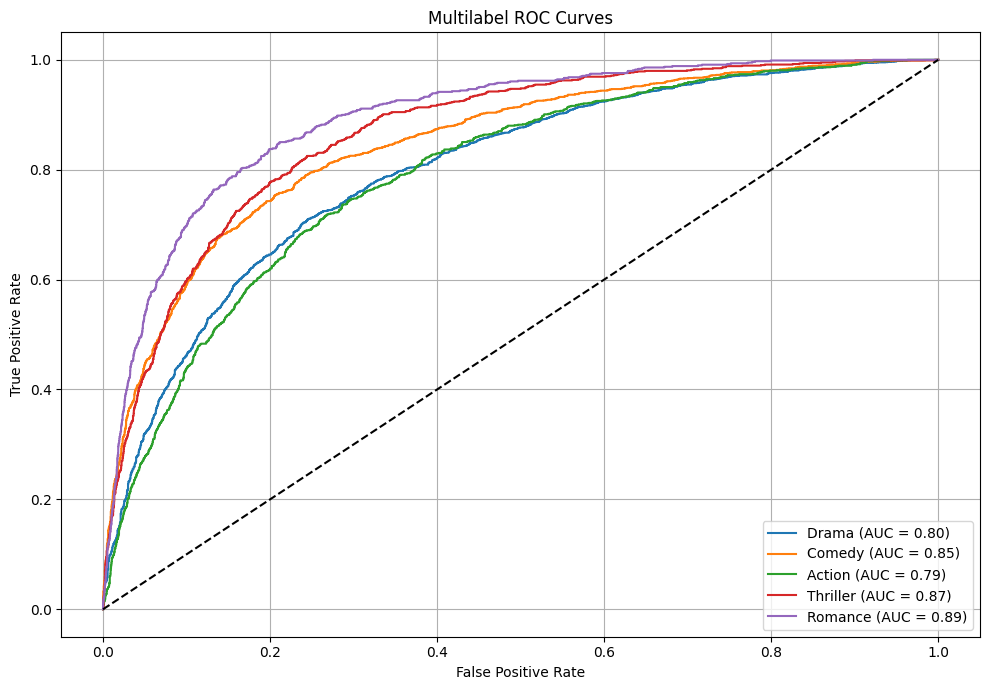

In [22]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

genre_names = ["Drama", "Comedy", "Action", "Thriller", "Romance"]  
n_classes = len(genre_names)


fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 7))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"{genre_names[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--')  
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multilabel ROC Curves")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig("roc_curves_GF.png")
plt.show()


In [23]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Parameters: {total:,}")
    print(f"Trainable Parameters: {trainable:,}")
    return total, trainable

total_params, trainable_params = count_parameters(model)


Total Parameters: 2,526,231
Trainable Parameters: 2,526,231


In [25]:
import torch
import time
import os
import pandas as pd

model = GatedFusionClassifier().to(device)


model.load_state_dict(torch.load("gated_fusion_model.pt", map_location=device))
model.eval()

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def benchmark_model(model, dataloader, device):
    model.to(device)
    model.eval()

    start = time.time()
    with torch.no_grad():
        for text_feat, image_feat, _ in dataloader:
            text_feat, image_feat = text_feat.to(device), image_feat.to(device)
            _ = model(text_feat, image_feat)
    total_time = time.time() - start
    avg_time = total_time / len(dataloader.dataset)

    torch.save(model.state_dict(), "temp_model.pt")
    model_size_mb = os.path.getsize("temp_model.pt") / (1024 * 1024)
    os.remove("temp_model.pt")

    total_params, trainable_params = count_parameters(model)

    df = pd.DataFrame({
        "Metric": ["Total Parameters", "Trainable Parameters", "Model Size (MB)", "Avg Inference Time (s/sample)"],
        "Value": [f"{total_params:,}", f"{trainable_params:,}", f"{model_size_mb:.2f}", f"{avg_time:.6f}"]
    })

    return df

summary = benchmark_model(model, val_loader, device)
summary.to_csv("gatedfusion_benchmark_summary.csv", index=False)

print(summary)



C:\Users\narah\AppData\Local\Temp\ipykernel_1868\2548608030.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("gated_fusion_model.pt", map

                          Metric      Value
0               Total Parameters  2,526,231
1           Trainable Parameters  2,526,231
2                Model Size (MB)       9.64
3  Avg Inference Time (s/sample)   0.000307


In [29]:
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss
import torch
import pandas as pd

# Prepare predictions and labels
preds = torch.cat(all_preds).numpy()
labels = torch.cat(all_labels).numpy()
preds_binary = (preds > 0.5).astype(int)
labels = labels.astype(int)

# Compute metrics
micro_f1 = f1_score(labels, preds_binary, average='micro')
macro_f1 = f1_score(labels, preds_binary, average='macro')
precision = precision_score(labels, preds_binary, average='micro')
recall = recall_score(labels, preds_binary, average='micro')
hamming = hamming_loss(labels, preds_binary)

# Save as a single-row CSV with model name
df = pd.DataFrame([{
    "Model": "GatedFusion",
    "Micro F1": micro_f1,
    "Macro F1": macro_f1,
    "Precision": precision,
    "Recall": recall,
    "Hamming Loss": hamming
}])

df.to_csv("gated_result.csv", index=False)
print("Saved: gated_result.csv'")


Saved: gated_result.csv'


### 🔍 Gated Fusion: Why & When It Helps

**Why it helps:**
- Learns to **dynamically weight** text and image inputs per sample.
- **Reduces noise** from less useful modalities.
- Improves **generalization** by focusing on the most relevant features.
- Enables **adaptive fusion** instead of static combination.

**When to use it:**
- When **modalities vary in importance** across samples.
- In **noisy or incomplete** multimodal data.
- For **multi-label tasks** where different labels rely on different inputs.

✅ In MM-IMDB, gated fusion improves performance by balancing plot (text) and poster (image) information effectively.
